Accuracy: 0.7073732718894009


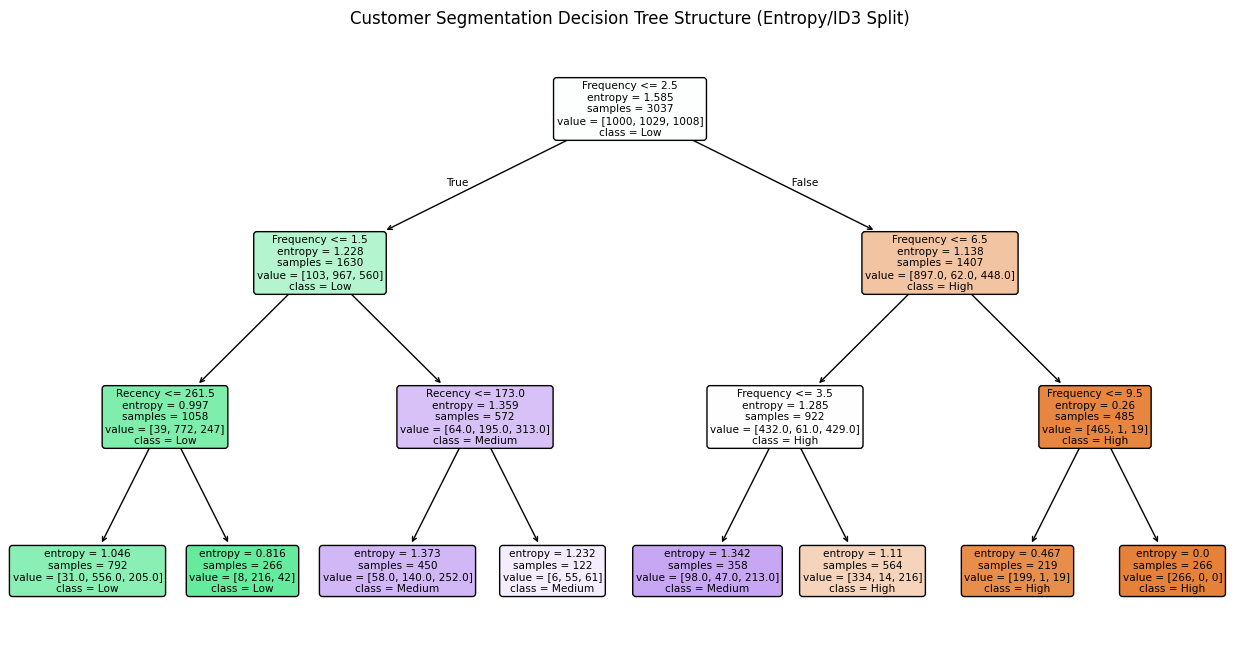

Feature Importance:
 Frequency    0.989739
Recency      0.010261
dtype: float64


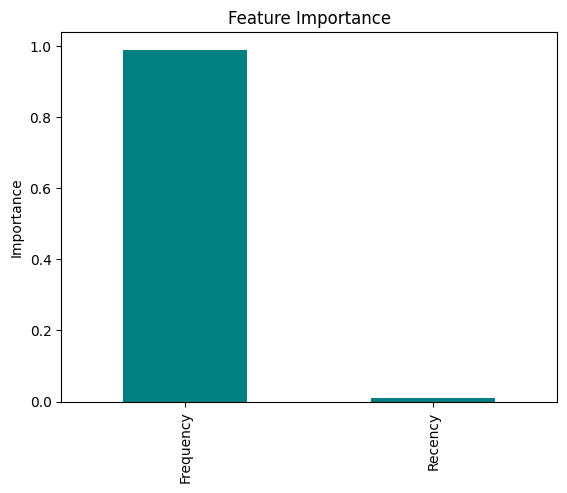

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Load Online Retail dataset
df = pd.read_excel("Online Retail.xlsx")

# Preprocess data
df = df.dropna(subset=['CustomerID'])
df = df[df['Quantity'] > 0]
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# Calculate customer purchasing behavior
customer = df.groupby('CustomerID').agg(
    LastPurchase=('InvoiceDate', 'max'),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum')
)

# Calculate Recency
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
customer['Recency'] = (
    snapshot_date - customer['LastPurchase']
).dt.days

customer = customer.drop(columns=['LastPurchase'])

# Create customer segments based on spending
customer['customer_segment'] = pd.qcut(
    customer['Monetary'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

# Select features and target
X = customer[['Recency', 'Frequency']]
y = customer['customer_segment']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Train ID3-style Decision Tree using Entropy
id3_tree = DecisionTreeClassifier(
    criterion='entropy', max_depth=3, random_state=42
)
id3_tree.fit(X_train, y_train)

# Evaluate model
y_pred = id3_tree.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

# Visualize decision tree
plt.figure(figsize=(16, 8))
plot_tree(
    id3_tree,
    feature_names=X.columns,
    class_names=id3_tree.classes_,
    filled=True,
    rounded=True
)
plt.title("Customer Segmentation Decision Tree Structure (Entropy/ID3 Split)")
plt.show()

# Display feature importance
importance = pd.Series(
    id3_tree.feature_importances_, index=X.columns
).sort_values(ascending=False)

print("Feature Importance:\n", importance)

importance.plot(kind='bar', color='teal')
plt.ylabel("Importance")
plt.title("Feature Importance")
plt.show()
